# Sleeves

One key component of the entire system is sleeves. These are certain assets which are held according to current market conditions. I will show in this notebook the effect they have together. These assets are not in the core since they do not necessarily perform well over the entire period, but primarily concentrated into certain market conditions.

In [1]:
import sys
from pathlib import Path
here = Path.cwd()
src = next(c for p in [here, *here.parents]
           for c in (p / "src", p / "isa_showcase" / "src", p / "isa_portfolio" / "isa_showcase" / "src",
                     p / "trading_portfolio" / "isa_portfolio" / "isa_showcase" / "src")
           if (c / "showcase_plots.py").exists())
sys.path.insert(0, str(src))
import pandas as pd
import showcase_plots as sp
sp.style()
d = sp.monthly()

## Contribution to the core

Lets begin with a table showcasing key statistics about the sleeves.

In [2]:
sp.table("parts_stats.csv").query("part == 'sleeves'").drop(columns="part").set_index("window")

,months,mean_pp_per_year,vol_pp_per_year,sharpe_of_contribution,best_month_pp,worst_month_pp,sum_pp,correlation_with_core
window,,,,,,,,
full 2001-02–2026-09,308,2.886,7.172,0.402,10.353,-9.481,74.073,-0.316
book 2006-01–2026-09,249,3.322,7.919,0.419,10.353,-9.481,68.923,-0.367
2001-05,59,1.047,1.943,0.539,1.451,-1.442,5.150,-0.035
2006-13,96,4.440,7.940,0.559,8.235,-4.411,35.522,-0.214
2014-19,72,-0.619,5.455,-0.113,5.778,-4.102,-3.713,-0.398
2020-26,81,5.498,9.564,0.575,10.353,-9.481,37.114,-0.538


The returns percentages are all relative to the core. Firstly notice that (combined), all sleeves have negative correlation with the core. This is important to me, since diversifying across assets is one thing that tends to perform well in positive market times, with the defensive basket protecting us otherwise. Moreover, notice the additional Sharpe contribution is positive in every time period apart from 2014-2019, where (combined), the sleeves reduce Sharpe slightly due to it being the strongest era for the core. In practice, looking at the last table in the notebook, the sleeves infact increases the Sharpe of the whole book, since they cut more risk than return.

## All sleeves combined

The following equity sleeve shows the approximate path of combined sleeves over time.

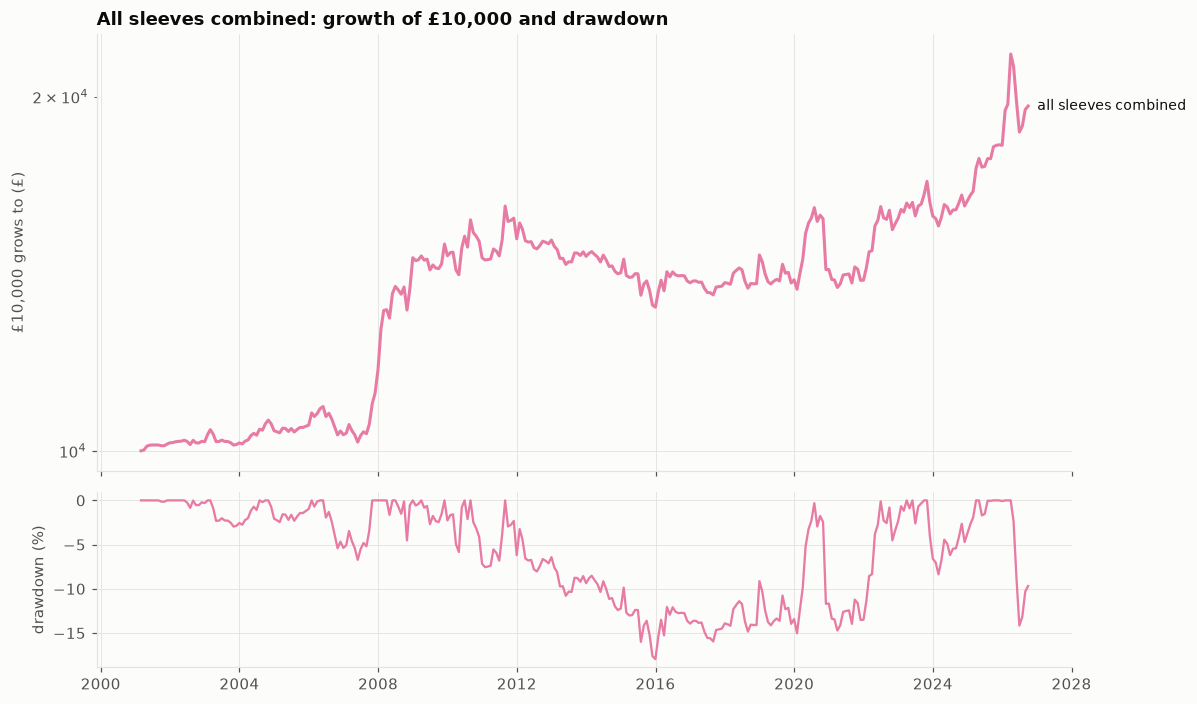

In [3]:
sp.curves({"all sleeves combined": d["sleeves"]}, {"all sleeves combined": sp.COLORS["sleeves"]}, "All sleeves combined: growth of £10,000 and drawdown")

It's not too difficult to notice that the sleeves (combined) seem to be more volatile than the core itself, so the combination of the two seeks to limit the risk from the sleeves, while keeping most of the returns. This is done in 'allocation'.

## The book with and without the sleeves

In [4]:
sp.table("layers_stats.csv").query("layers in ['core + defensive + rebound + overlay', 'book (all five parts)']").set_index(["window", "layers"]).sort_index()

months  sharpe  cagr_pct  vol_pct  max_drawdown_pct  final_gbp_from_10k
window               layers                                                                                                       
2001-05              book (all five parts)                     59   1.192    16.884    9.924            -7.462          21,534.440
                     core + defensive + rebound + overlay      59   1.019    15.608   10.587            -7.230          20,402.434
2006-13              book (all five parts)                     96   1.315    18.005   11.495            -9.940          37,600.386
                     core + defensive + rebound + overlay      96   0.812    12.720   13.160           -19.772          26,061.606
2014-19              book (all five parts)                     72   1.494    14.406    8.980            -7.998          22,422.726
                     core + defensive + rebound + overlay      72   1.427    15.013    9.839           -10.542          23,145.896
2020-26              book (all five parts)                     81   2.015    21.717    8.637            -5.383          37,681.093
                     core + defensive + rebound + overlay      81   0.935    14.814   12.730           -14.622          25,407.773
book 2006-01–2026-09 book (all five parts)                    249   1.553    18.137    9.898            -9.940         317,690.484
                     core + defensive + rebound + overlay     249   0.996    14.059   12.103           -19.772         153,264.566
full 2001-02–2026-09 book (all five parts)                    308   1.485    17.896    9.895            -9.940         684,128.666
                     core + defensive + rebound + overlay     308   1.000    14.354   11.812           -19.772         312,697.020

Notice immediately the seeming 'contradiction' in the 2014-2019 period. That is due to the returns in the above table being relative to the core, and since the sleeves underperformed the core in that period, its Sharpe contribution is negative despite actually increasing the Sharpe of the book. On the whole, the combined sleeves increase the Sharpe of the book in every time period, significantly in 2020-2026 with over half of the Sharpe being from the sleeves, but this trend applies across the board, not just recently.

## Before 2001

The sleeves were developed in-sample on 2001-2026. So, we pose the question, how well do they hold up on a completely different era?

In [5]:
L = sp.long_parts().rename(columns={"core_defensive_rebound": "without sleeves", "with_sleeves": "with sleeves"})
recent = pd.DataFrame({"without sleeves": d["core"] + d["defensive"] + d["rebound"],
                       "with sleeves": d["core"] + d["defensive"] + d["rebound"] + d["sleeves"], "cash": d["cash"]})
rows = []
for label, df, a, b in [("1979–1989", L, "1979", "1989"), ("1990–2000", L, "1990", "2001-01"), ("2001–2026", recent, "2001", "2026")]:
    t = sp.period_table(df.loc[a:b], {"without": "without sleeves", "with": "with sleeves"})
    rows.append({"period": label, "cash rate %": t.attrs["cash"],
                 "CAGR % without": t.loc["without", "CAGR %"], "CAGR % with": t.loc["with", "CAGR %"],
                 "Sharpe without": t.loc["without", "Sharpe over cash"], "Sharpe with": t.loc["with", "Sharpe over cash"],
                 "return/vol without": t.loc["without", "return / vol"], "return/vol with": t.loc["with", "return / vol"],
                 "max DD % without": t.loc["without", "max drawdown %"], "max DD % with": t.loc["with", "max drawdown %"]})
pd.DataFrame(rows).set_index("period").round(2)

,cash rate %,CAGR % without,CAGR % with,Sharpe without,Sharpe with,return/vol without,return/vol with,max DD % without,max DD % with
period,,,,,,,,,
1979–1989,12.610,25.610,22.600,0.620,0.540,1.180,1.160,-37.560,-31.370
1990–2000,7.970,10.730,11.490,0.240,0.300,0.720,0.880,-33.450,-13.910
2001–2026,2.390,13.320,16.820,0.920,1.380,1.130,1.610,-19.770,-9.940


In 1979-1989, the sleeves actually reduce the CAGR of the core. When investigated further, this was tied almost entirely to one asset, which had a terrible bear period here. Economically, it was correlated with the height of interest rates. Despite this, the Sharpe difference wasn't too large, and the sleeves still cut drawdown here. In the following decade, the pattern reversed, and the sleeves were beneficial to the book in all ways, Sharpe, CAGR, and cutting max drawdown by ~20%. The added Sharpe was not as large as it was in the rest of the time period, but it was still beneficial, despite the bear period continuing from the previous decade.